# Anomaly detection with Principal Component Analysis (PCA)

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# Load data
using a url to a shared google drive

In [ ]:
url = "https://drive.google.com/uc?export=download&id=1Ev8LxlHvcdxndLWbk1ycbR90YjDfClfm"

# Load the CSV into a DataFrame directly from the URL
data = pd.read_csv(url)

# Display the first few rows to confirm
data

,Time (days),Ambient Temperature,Bearing Temperature,Label
0,0.000000,20.248357,30.579798,0.0
1,0.041696,21.225842,31.812579,0.0
2,0.083391,22.825420,32.915930,0.0
3,0.125087,24.298978,33.650562,0.0
4,0.166782,24.214868,34.414712,0.0
...,...,...,...,...
1435,59.833218,15.809345,25.354503,0.0
1436,59.874913,16.338191,25.869938,0.0
1437,59.916609,18.302097,27.968208,0.0
1438,59.958304,18.950514,29.096610,0.0


# Visualize the data

### on the time axis

Text(0, 0.5, 'Ambient temperature')

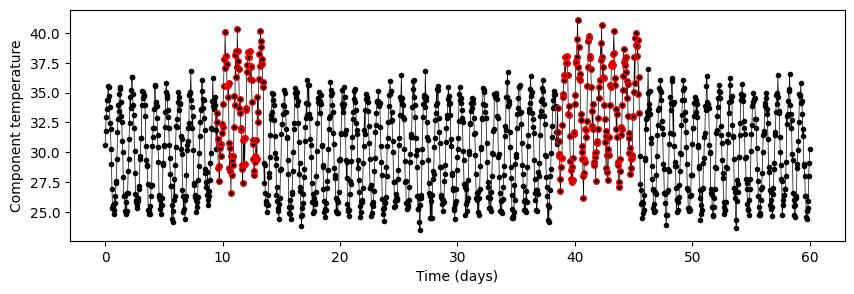

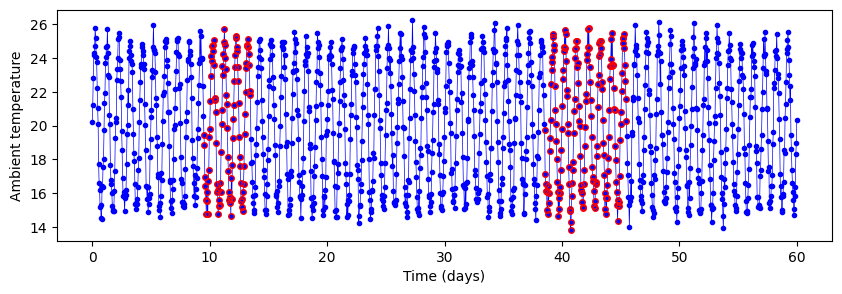

In [ ]:
# Highlight true anomalies in red
true_anomalies = data.loc[data['Label']==1]  # Use the indices of the true anomalies

plt.figure(figsize=(10,3))
plt.plot(data['Time (days)'],data['Bearing Temperature'],'k-o',lw=0.5,ms=3)
plt.plot(true_anomalies['Time (days)'],true_anomalies['Bearing Temperature'],'ro',markerfacecolor='none',ms=4)

plt.xlabel('Time (days)')
plt.ylabel('Component temperature')

plt.figure(figsize=(10,3))
plt.plot(data['Time (days)'],data['Ambient Temperature'],'b-o',lw=0.5,ms=3)
plt.plot(true_anomalies['Time (days)'],true_anomalies['Ambient Temperature'],'ro',markerfacecolor='none',ms=4)

plt.xlabel('Time (days)')
plt.ylabel('Ambient temperature')


### pair plot

In [ ]:
import itertools

def pair_plot(df_data):
  # Create a pair plot
  num_vars = df_data.columns
  n = len(num_vars)

  fig, axes = plt.subplots(n, n, figsize=(5, 5))

  # Iterate through each subplot
  for i, j in itertools.product(range(n), range(n)):
      ax = axes[i, j]
      if i == j:
          # Diagonal: Plot histograms
          ax.hist(df_data[num_vars[i]], bins=50, color='lightblue', edgecolor='black')
          ax.set_title(num_vars[i])
      else:
          # Off-diagonal: Scatter plots
          ax.scatter(df_data[num_vars[j]], df_data[num_vars[i]], alpha=0.5, color='blue',s=2)

  # Adjust layout
  plt.tight_layout()
  plt.show()
  return fig,axes


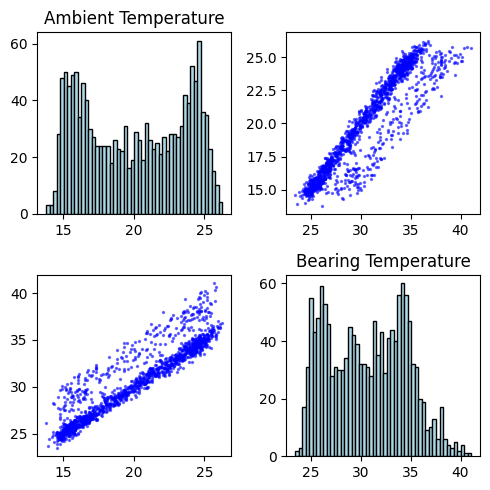

<Figure size 640x480 with 0 Axes>

In [ ]:
var_data = data[["Ambient Temperature","Bearing Temperature"]].copy()
fig,axes = pair_plot(var_data)

plt.tight_layout()
#fig.savefig('BearingTempAmbient_PairPlot.pdf')  # Save the figure

# Download the figure
#files.download('BearingTempAmbient_PairPlot.pdf')

# Split to train and test data
Train with normal data only ==> use the first 9 days.
Test with everything.

In [ ]:


# Assuming `data` contains columns ['Time (days)', 'Ambient Temperature', 'Bearing Temperature', 'Labels']

# Parameters
N = 9  # Number of days for training (time range)
threshold_percentile = 95  # Percentile for threshold determination

# Step 1: Create overlapping time windows and timestamps
def create_time_windows_with_timestamps(data, timestamps, window_size):
    """
    Create overlapping time windows and associate each with its end timestamp.
    """
    windows = []
    window_timestamps = []
    for i in range(len(data) - window_size + 1):
        window = data[i:i + window_size].values.flatten()  # Flatten window across features
        windows.append(window)
        window_timestamps.append(timestamps[i + window_size - 1])  # Use the end timestamp
    return np.array(windows), np.array(window_timestamps)

# Extract features and labels
time_series_data = data[['Ambient Temperature', 'Bearing Temperature']]
timestamps = data['Time (days)'].values
labels = data['Label']  # Binary labels: 0 = normal, 1 = abnormal

# Split data into training and test sets based on time
train_data = time_series_data[data['Time (days)'] <= N]
train_timestamps = timestamps[data['Time (days)'] <= N]
train_labels = labels[data['Time (days)'] <= N]
test_data = time_series_data
test_timestamps = timestamps
test_labels = labels



# PCA on single time stamps
The data is generated with windows of size M. Setting M=1 we resort to an input size of a single time step (for both vaiables).

In [ ]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


In [ ]:
M = 1  # Set the window length to 1

# Create overlapping windows and timestamps for training and testing
train_windows, train_window_timestamps = create_time_windows_with_timestamps(train_data, train_timestamps, M)
test_windows, test_window_timestamps = create_time_windows_with_timestamps(test_data, test_timestamps, M)

# Standardize the data using the training data
scaler = StandardScaler()
train_windows_scaled = scaler.fit_transform(train_windows)
test_windows_scaled = scaler.transform(test_windows)

# Train PCA on training data
pca = PCA(n_components=1)  # input has 2 dimensions --> reduce to 1.
pca.fit(train_windows_scaled)

# Reconstruct and calculate reconstruction errors
train_reconstructed = pca.inverse_transform(pca.transform(train_windows_scaled))
test_reconstructed = pca.inverse_transform(pca.transform(test_windows_scaled))

train_reconstruction_error = np.mean((train_windows_scaled - train_reconstructed) ** 2, axis=1)
test_reconstruction_error = np.mean((test_windows_scaled - test_reconstructed) ** 2, axis=1)




## number of input features and principal components


In [ ]:
print("PCA reduced the dimension from ",pca.n_features_in_,' to ', pca.n_components_)

PCA reduced the dimension from  2  to  1


## Plot histogram of reconstruction errors

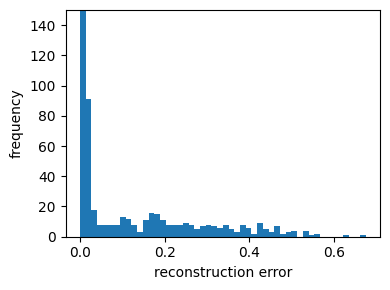

In [ ]:
fig=plt.figure(figsize=(4,3))
hist_re = plt.hist(test_reconstruction_error,50)
plt.xlabel('reconstruction error')
plt.ylabel('frequency')
plt.ylim(0,150)
plt.tight_layout()

#fig.savefig('PCA_ReconErrors_hist.pdf')  # Save the figure

# Download the figure
#from google.colab import files
#files.download('PCA_ReconErrors_hist.pdf')

## Determine detection threshold

### Statistical threshold

In [ ]:
# Set threshold at the tail of the training reconstruction error distribution
threshold = np.percentile(train_reconstruction_error, threshold_percentile)

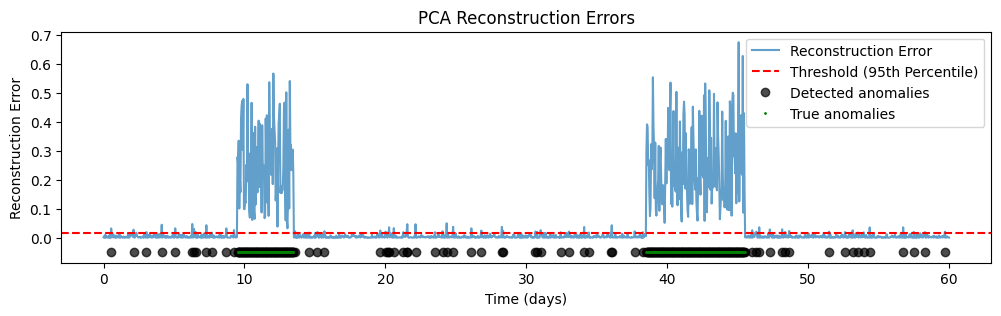

In [ ]:
# Detect anomalies in the test set
test_anomalies = test_reconstruction_error > threshold
# Plot reconstruction errors and backward-looking moving mean
plt.figure(figsize=(12, 3))
plt.plot(test_window_timestamps, test_reconstruction_error, label="Reconstruction Error", alpha=0.7)
plt.axhline(threshold, color='red', linestyle='--', label=f"Threshold ({threshold_percentile}th Percentile)")
plt.plot(test_window_timestamps[test_anomalies],0*test_window_timestamps[test_anomalies]-0.05,'ok',label='Detected anomalies', alpha=0.7)
plt.plot(true_anomalies['Time (days)'],0*true_anomalies['Bearing Temperature']-0.05,'g.',ms=2,label='True anomalies')

plt.xlabel("Time (days)")
plt.ylabel("Reconstruction Error")
plt.legend()
plt.title("PCA Reconstruction Errors")
plt.show()



### Geometric threshold

inspecting the recon-error histogram, find the start of the tail by requiring that the hist frequency goes for the first time below a certain threshold. This assumes that most of the normal data obtains reconstructions errors that create a peak close to 0.

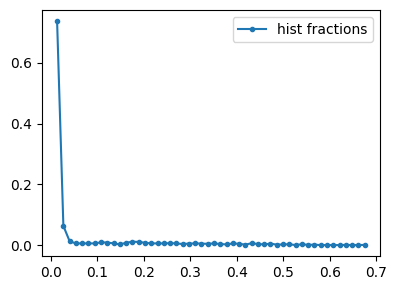

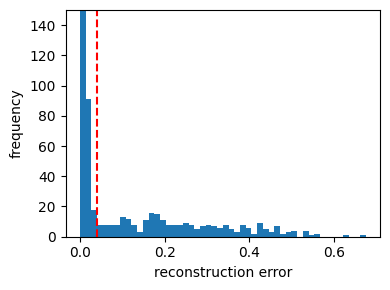

In [ ]:
# plot the relative fraction of the errors
fig=plt.figure(figsize=(4,3))
plt.plot(hist_re[1][1:],hist_re[0]/np.sum(hist_re[0]),'.-',label='hist fractions')
# define the histogram tail starting from a small fraction of 0.01
tail_start = np.min(np.where(hist_re[0]/np.sum(hist_re[0])<0.01)[0])
# find the value at the tail start
thresh_tail = hist_re[1][tail_start]
#sum over the frequqencies up to tail_start to estimate the number of anomalies
Nanomalies_est = np.sum(hist_re[0]) - np.sum(hist_re[0][:tail_start])
plt.legend()
plt.tight_layout()

fig=plt.figure(figsize=(4,3))
hist_re = plt.hist(test_reconstruction_error,50)
plt.axvline(thresh_tail,color='r',linestyle='--')
plt.xlabel('reconstruction error')
plt.ylabel('frequency')
plt.ylim(0,150)
plt.tight_layout()

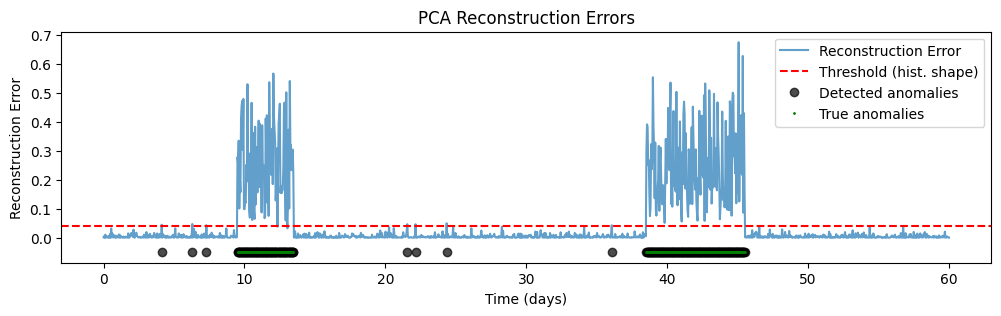

In [ ]:
# Classify anomalies in the test set with the geometric threshold
test_anomalies = test_reconstruction_error > thresh_tail
# Plot reconstruction errors and backward-looking moving mean
plt.figure(figsize=(12, 3))
plt.plot(test_window_timestamps, test_reconstruction_error, label="Reconstruction Error", alpha=0.7)
plt.axhline(thresh_tail, color='red', linestyle='--', label=f"Threshold (hist. shape)")
plt.plot(test_window_timestamps[test_anomalies],0*test_window_timestamps[test_anomalies]-0.05,'ok',label='Detected anomalies', alpha=0.7)
plt.plot(true_anomalies['Time (days)'],0*true_anomalies['Bearing Temperature']-0.05,'g.',ms=2,label='True anomalies')

plt.xlabel("Time (days)")
plt.ylabel("Reconstruction Error")
plt.legend()
plt.title("PCA Reconstruction Errors")
plt.show()

## Think
1. Can you suggest another way to avoid many false positives? Hint: look at the time depenence of the reconstruction errors.

## Threshold on moving mean of reconstruction errors

In [ ]:
def moving_mean_backward(data, window_size):
    """
    Calculate the moving mean with a backward-looking window.
    Only includes the current value and previous values in the window.
    """
    moving_mean = np.zeros_like(data)
    for i in range(len(data)):
        start_idx = max(0, i - window_size + 1)  # Start of the window
        moving_mean[i] = np.mean(data[start_idx:i + 1])  # Backward-looking mean
    return moving_mean


### Statistical threshold

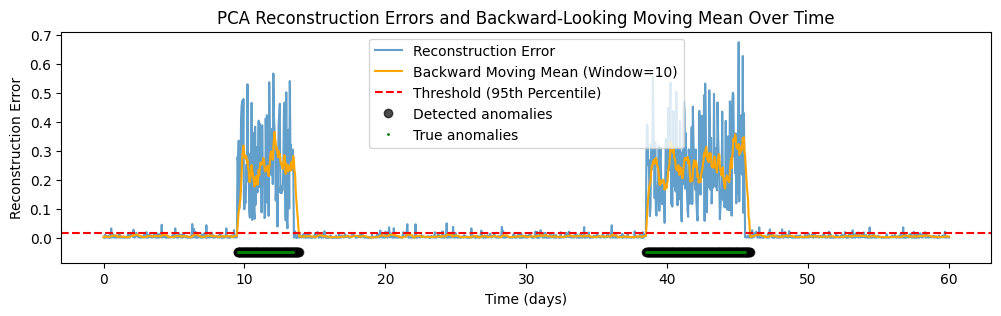

In [ ]:
# Parameters for moving mean
moving_mean_window_size = 10  # Hyperparameter

# Calculate the backward-looking moving mean for test reconstruction errors
moving_mean_errors = moving_mean_backward(test_reconstruction_error, moving_mean_window_size)

# Set threshold based on training reconstruction error
moving_mean_errors_train = moving_mean_backward(train_reconstruction_error, moving_mean_window_size)

#threshold_moving_mean = np.percentile(moving_mean_errors_train, threshold_percentile)

# Detect anomalies in the test set using the statistical threshold as before
test_anomalies = moving_mean_errors > threshold
# Plot reconstruction errors and backward-looking moving mean
plt.figure(figsize=(12, 3))
plt.plot(test_window_timestamps, test_reconstruction_error, label="Reconstruction Error", alpha=0.7)
plt.plot(test_window_timestamps, moving_mean_errors, label=f"Backward Moving Mean (Window={moving_mean_window_size})", color='orange')
plt.axhline(threshold, color='red', linestyle='--', label=f"Threshold ({threshold_percentile}th Percentile)")
plt.plot(test_window_timestamps[test_anomalies],0*test_window_timestamps[test_anomalies]-0.05,'ok',label='Detected anomalies', alpha=0.7)
#plt.plot(data.loc[anomaly_mask,'Time (days)'],0*data.loc[anomaly_mask,'Time (days)']-0.05,'g.',label='True anomalies')
plt.plot(true_anomalies['Time (days)'],0*true_anomalies['Bearing Temperature']-0.05,'g.',ms=2,label='True anomalies')

plt.xlabel("Time (days)")
plt.ylabel("Reconstruction Error")
plt.legend()
plt.title("PCA Reconstruction Errors and Backward-Looking Moving Mean Over Time")
plt.show()



### Histogram of smoothed reconstruction errors

(0.0, 150.0)

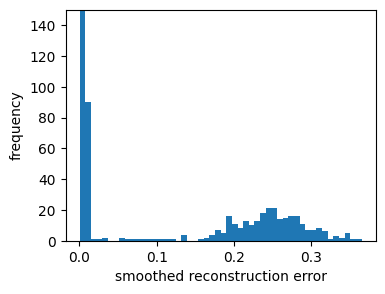

In [ ]:
plt.figure(figsize=(4,3))
hist_re = plt.hist(moving_mean_errors,50)
plt.xlabel('smoothed reconstruction error')
plt.ylabel('frequency')
plt.ylim(0,150)

### Geometric threshold

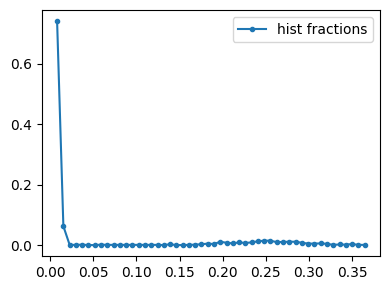

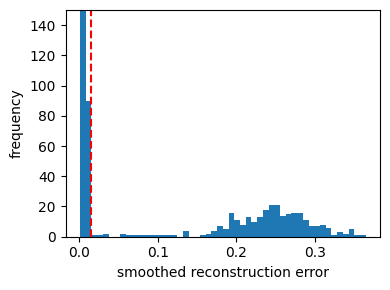

In [ ]:
# plot the relative fraction of the errors
fig=plt.figure(figsize=(4,3))
plt.plot(hist_re[1][1:],hist_re[0]/np.sum(hist_re[0]),'.-',label='hist fractions')
# define the histogram tail starting from a small fraction of 0.01
tail_start = np.min(np.where(hist_re[0]/np.sum(hist_re[0])<0.01)[0])
# find the value at the tail start
thresh_tail = hist_re[1][tail_start]
#sum over the frequqencies up to tail_start to estimate the number of anomalies
Nanomalies_est = np.sum(hist_re[0]) - np.sum(hist_re[0][:tail_start])
plt.legend()
plt.tight_layout()

fig=plt.figure(figsize=(4,3))
hist_re = plt.hist(moving_mean_errors,50)
plt.axvline(thresh_tail,color='r',linestyle='--')
plt.xlabel('smoothed reconstruction error')
plt.ylabel('frequency')
plt.ylim(0,150)
plt.tight_layout()

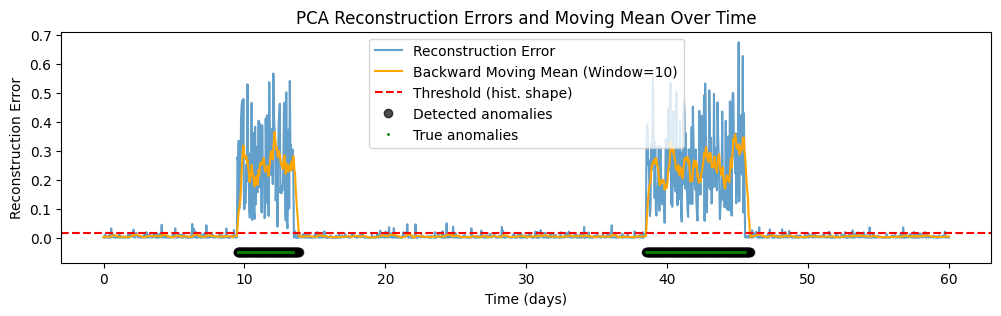

In [ ]:
# Detect anomalies in the test set
test_anomalies = moving_mean_errors > thresh_tail
# Plot reconstruction errors and backward-looking moving mean
plt.figure(figsize=(12, 3))
plt.plot(test_window_timestamps, test_reconstruction_error, label="Reconstruction Error", alpha=0.7)
plt.plot(test_window_timestamps, moving_mean_errors, label=f"Backward Moving Mean (Window={moving_mean_window_size})", color='orange')
plt.axhline(threshold, color='red', linestyle='--', label=f"Threshold (hist. shape)")
plt.plot(test_window_timestamps[test_anomalies],0*test_window_timestamps[test_anomalies]-0.05,'ok',label='Detected anomalies', alpha=0.7)
#plt.plot(data.loc[anomaly_mask,'Time (days)'],0*data.loc[anomaly_mask,'Time (days)']-0.05,'g.',label='True anomalies')
plt.plot(true_anomalies['Time (days)'],0*true_anomalies['Bearing Temperature']-0.05,'g.',ms=2,label='True anomalies')

plt.xlabel("Time (days)")
plt.ylabel("Reconstruction Error")
plt.legend()
plt.title("PCA Reconstruction Errors and Moving Mean Over Time")
plt.show()

## Think
1. what are the pros and cons of the smoothing approach?
2. which approach is more robust?
3. Find out how early we detect the fault with each of the methods.

# Evaluation: precision recall

## Define anomaly scores as reconstruction errors

In [ ]:
anomaly_scores = moving_mean_errors
true_labels = data['Label']

## Own precision-recall calculation

In [ ]:
def calculate_precision_recall_from_scratch(anomaly_scores, true_labels, threshold_array):
    """
    Calculate precision and recall for a given set of thresholds from scratch.

    Parameters:
    - anomaly_scores: Array-like, the anomaly scores output by the isolation forest.
                      Higher scores indicate a higher likelihood of being an anomaly.
    - true_labels: Array-like, ground truth labels (0 for normal, 1 for anomalies).
    - threshold_array: List or array of thresholds to evaluate.

    Returns:
    - precision: List of precision values for each threshold.
    - recall: List of recall values for each threshold.
    """
    precision = []
    recall = []

    for threshold in threshold_array:
        # Classify points as anomalies (1) or normal (0) based on the threshold
        predicted_labels = (anomaly_scores >= threshold).astype(int)

        # True Positives, False Positives, False Negatives
        tp = ((predicted_labels == 1) & (true_labels == 1)).sum()
        fp = ((predicted_labels == 1) & (true_labels == 0)).sum()
        fn = ((predicted_labels == 0) & (true_labels == 1)).sum()

        # Precision and Recall calculations
        prec = tp / (tp + fp) if (tp + fp) > 0 else 0
        rec = tp / (tp + fn) if (tp + fn) > 0 else 0

        precision.append(prec)
        recall.append(rec)

    return precision, recall



In [ ]:
threshold_arr = np.arange(np.min(anomaly_scores),np.max(anomaly_scores),0.01)
threshold_arr

array([0.00059858, 0.01059858, 0.02059858, 0.03059858, 0.04059858,
       0.05059858, 0.06059858, 0.07059858, 0.08059858, 0.09059858,
       0.10059858, 0.11059858, 0.12059858, 0.13059858, 0.14059858,
       0.15059858, 0.16059858, 0.17059858, 0.18059858, 0.19059858,
       0.20059858, 0.21059858, 0.22059858, 0.23059858, 0.24059858,
       0.25059858, 0.26059858, 0.27059858, 0.28059858, 0.29059858,
       0.30059858, 0.31059858, 0.32059858, 0.33059858, 0.34059858,
       0.35059858, 0.36059858])

In [ ]:
precision_test, recall_test = calculate_precision_recall_from_scratch(anomaly_scores, true_labels, threshold_arr)

## Precision-recall curve

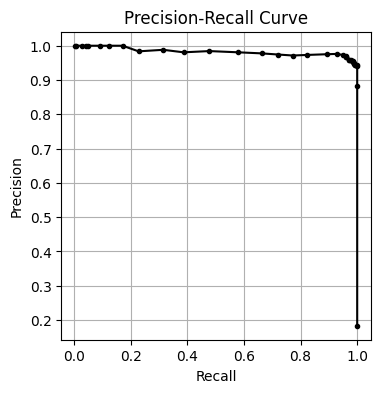

In [ ]:
plt.figure(figsize=(4, 4))
plt.plot(recall_test,precision_test,'ko-',ms=3)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.grid()
plt.show()

## Plot detected anomalies on the time axis

Text(0, 0.5, 'Component temperature')

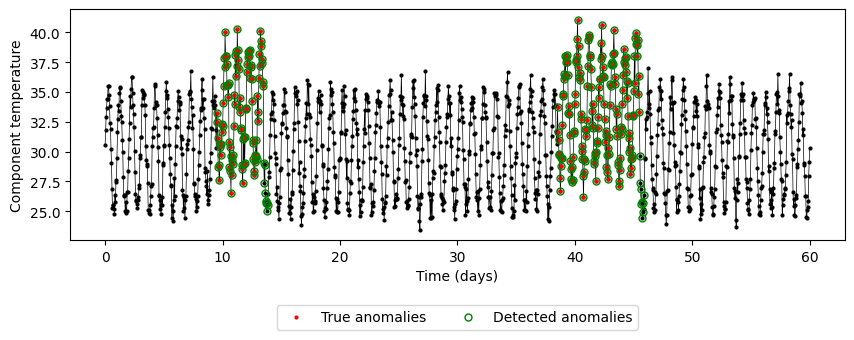

In [ ]:
# Highlight true anomalies with large empty yellow squares
detection_mask_test = moving_mean_errors > thresh_tail
detected_anomalies_test = test_data.loc[detection_mask_test]


plt.figure(figsize=(10,3))
plt.plot(data['Time (days)'],data['Bearing Temperature'],'k-o',lw=0.5,ms=2)
plt.plot(true_anomalies['Time (days)'],true_anomalies['Bearing Temperature'],'ro',ms=2,label='True anomalies')
plt.plot(timestamps[detection_mask_test],detected_anomalies_test['Bearing Temperature'],'go',markerfacecolor='none',ms=5,label='Detected anomalies')

plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.25), ncol=3)

plt.xlabel('Time (days)')
plt.ylabel('Component temperature')


# PCA on time series

In [ ]:
M = 10  # Length of time window

# Create overlapping windows and timestamps for training and testing
train_windows, train_window_timestamps = create_time_windows_with_timestamps(train_data, train_timestamps, M)
test_windows, test_window_timestamps = create_time_windows_with_timestamps(test_data, test_timestamps, M)
train_labels_win = train_labels[M-1:]
test_labels_win = test_labels[M-1:]
test_data_reduced = test_data[M-1:]

# Standardize the data using the training data
scaler = StandardScaler()
train_windows_scaled = scaler.fit_transform(train_windows)
test_windows_scaled = scaler.transform(test_windows)

# Train PCA on training data
pca = PCA(n_components=2)  # any number between 1 and 19
pca.fit(train_windows_scaled)

# Reconstruct and calculate reconstruction errors
train_reconstructed = pca.inverse_transform(pca.transform(train_windows_scaled))
test_reconstructed = pca.inverse_transform(pca.transform(test_windows_scaled))

train_reconstruction_error = np.mean((train_windows_scaled - train_reconstructed) ** 2, axis=1)
test_reconstruction_error = np.mean((test_windows_scaled - test_reconstructed) ** 2, axis=1)


## number of input features and principal components

In [ ]:
print("PCA reduced the dimension from ",pca.n_features_in_,' to ', pca.n_components_)

PCA reduced the dimension from  20  to  2


## Optional: select the number of principal components

In [ ]:
# how much of the variance in the data would you like to explain?
frac_explained_variance = 0.99 # change this to see the effect
pca_optional = PCA(n_components=frac_explained_variance)
pca_optional.fit(train_windows_scaled)
print("PCA reduced the dimension from ",pca_optional.n_features_in_,' to ', pca_optional.n_components_)

PCA reduced the dimension from  20  to  7


### Statistical threshold

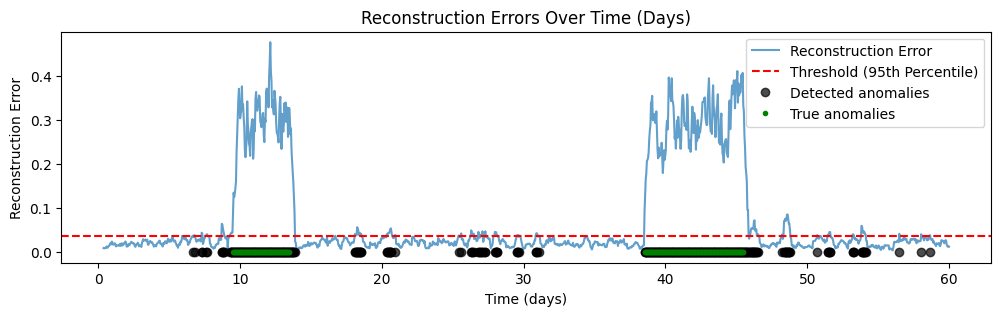

Threshold: 0.03756052067773822
Detected Anomalies: 393


In [ ]:
# Set threshold based on training reconstruction error
threshold = np.percentile(train_reconstruction_error, threshold_percentile)

# Detect anomalies in the test set
test_anomalies = test_reconstruction_error > threshold

# Plot reconstruction errors vs. Time (days)
plt.figure(figsize=(12, 3))
plt.plot(test_window_timestamps, test_reconstruction_error, label="Reconstruction Error", alpha=0.7)
plt.axhline(threshold, color='red', linestyle='--', label=f"Threshold ({threshold_percentile}th Percentile)")
plt.plot(test_window_timestamps[test_anomalies],0*test_window_timestamps[test_anomalies],'ok',label='Detected anomalies', alpha=0.7)
plt.plot(true_anomalies['Time (days)'],0*true_anomalies['Bearing Temperature'],'g.',label='True anomalies')

plt.xlabel("Time (days)")
plt.ylabel("Reconstruction Error")
plt.legend()
plt.title("Reconstruction Errors Over Time (Days)")
plt.show()

# Print summary of results
print("Threshold:", threshold)
print("Detected Anomalies:", np.sum(test_anomalies))

### Histogram of reconstruction errors

(0.0, 150.0)

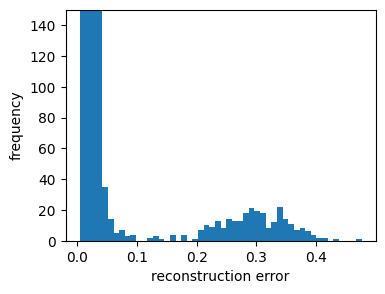

In [ ]:
plt.figure(figsize=(4,3))
hist_re = plt.hist(test_reconstruction_error,50)
plt.xlabel('reconstruction error')
plt.ylabel('frequency')
plt.ylim(0,150)

### Geometric threshold

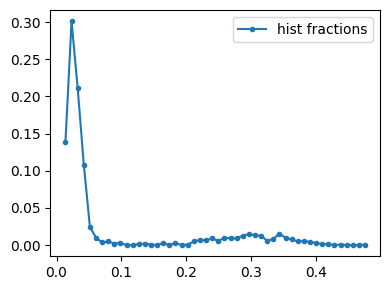

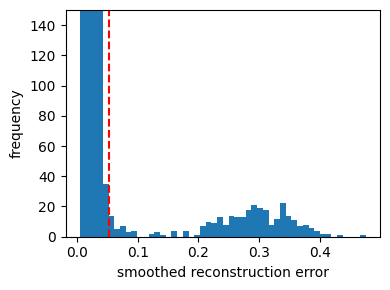

In [ ]:
# plot the relative fraction of the errors
fig=plt.figure(figsize=(4,3))
plt.plot(hist_re[1][1:],hist_re[0]/np.sum(hist_re[0]),'.-',label='hist fractions')
# define the histogram tail starting from a small fraction of 0.01
tail_start = np.min(np.where(hist_re[0]/np.sum(hist_re[0])<0.01)[0])
# find the value at the tail start
thresh_tail = hist_re[1][tail_start]
#sum over the frequqencies up to tail_start to estimate the number of anomalies
Nanomalies_est = np.sum(hist_re[0]) - np.sum(hist_re[0][:tail_start])
plt.legend()
plt.tight_layout()

fig=plt.figure(figsize=(4,3))
hist_re = plt.hist(test_reconstruction_error,50)
plt.axvline(thresh_tail,color='r',linestyle='--')
plt.xlabel('smoothed reconstruction error')
plt.ylabel('frequency')
plt.ylim(0,150)
plt.tight_layout()

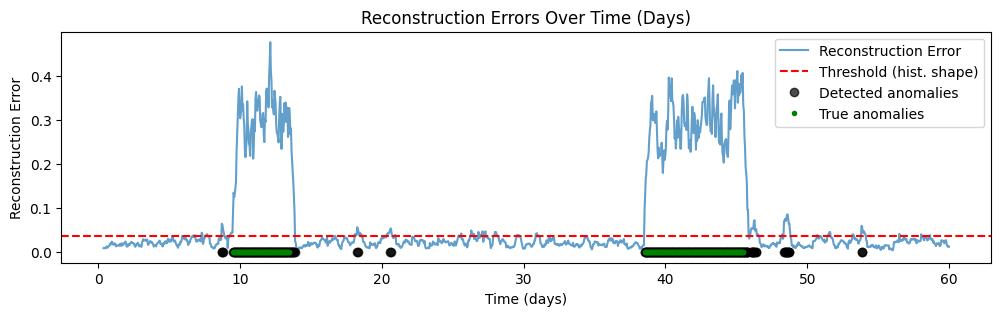

Threshold: 0.03756052067773822
Detected Anomalies: 309


In [ ]:
# Detect anomalies in the test set
test_anomalies = test_reconstruction_error > thresh_tail

# Plot reconstruction errors vs. Time (days)
plt.figure(figsize=(12, 3))
plt.plot(test_window_timestamps, test_reconstruction_error, label="Reconstruction Error", alpha=0.7)
plt.axhline(threshold, color='red', linestyle='--', label=f"Threshold (hist. shape)")
plt.plot(test_window_timestamps[test_anomalies],0*test_window_timestamps[test_anomalies],'ok',label='Detected anomalies', alpha=0.7)
plt.plot(true_anomalies['Time (days)'],0*true_anomalies['Bearing Temperature'],'g.',label='True anomalies')

plt.xlabel("Time (days)")
plt.ylabel("Reconstruction Error")
plt.legend()
plt.title("Reconstruction Errors Over Time (Days)")
plt.show()

# Print summary of results
print("Threshold:", threshold)
print("Detected Anomalies:", np.sum(test_anomalies))

## Threshold on moving mean of reconstruction errors

In [ ]:
# Parameters for moving mean
moving_mean_window_size = 10  # Adjust as needed

# Calculate the backward-looking moving mean for test reconstruction errors
moving_mean_errors = moving_mean_backward(test_reconstruction_error, moving_mean_window_size)

# Set threshold based on training reconstruction error
moving_mean_errors_train = moving_mean_backward(train_reconstruction_error, moving_mean_window_size)

#threshold_moving_mean = np.percentile(moving_mean_errors_train, threshold_percentile)



### Statistical threshold

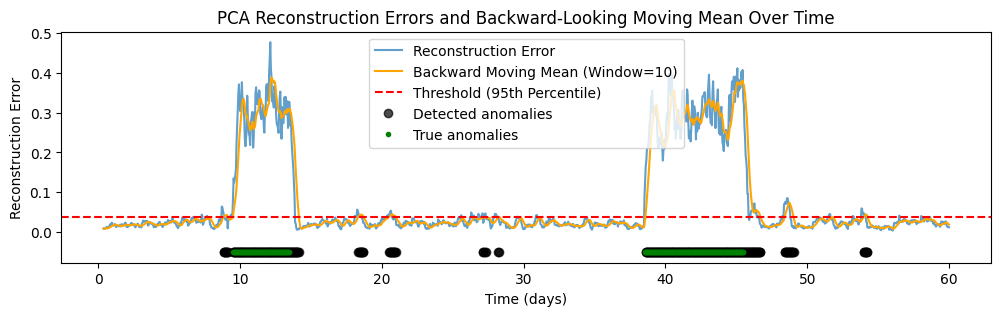

In [ ]:
# Detect anomalies in the test set
test_anomalies = moving_mean_errors > threshold
# Plot reconstruction errors and backward-looking moving mean
plt.figure(figsize=(12, 3))
plt.plot(test_window_timestamps, test_reconstruction_error, label="Reconstruction Error", alpha=0.7)
plt.plot(test_window_timestamps, moving_mean_errors, label=f"Backward Moving Mean (Window={moving_mean_window_size})", color='orange')
plt.axhline(threshold, color='red', linestyle='--', label=f"Threshold ({threshold_percentile}th Percentile)")
plt.plot(test_window_timestamps[test_anomalies],0*test_window_timestamps[test_anomalies]-0.05,'ok',label='Detected anomalies', alpha=0.7)
plt.plot(true_anomalies['Time (days)'],0*true_anomalies['Bearing Temperature']-0.05,'g.',label='True anomalies')

plt.xlabel("Time (days)")
plt.ylabel("Reconstruction Error")
plt.legend()
plt.title("PCA Reconstruction Errors and Backward-Looking Moving Mean Over Time")
plt.show()

### Histograms of reconstruction errors

(0.0, 150.0)

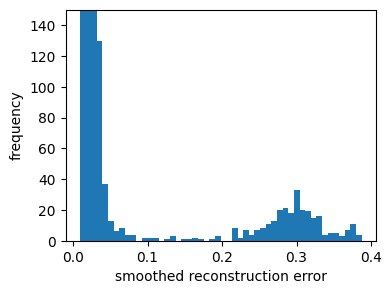

In [ ]:
plt.figure(figsize=(4,3))
hist_re = plt.hist(moving_mean_errors,50)
plt.xlabel('smoothed reconstruction error')
plt.ylabel('frequency')
plt.ylim(0,150)

### Geometric threshold

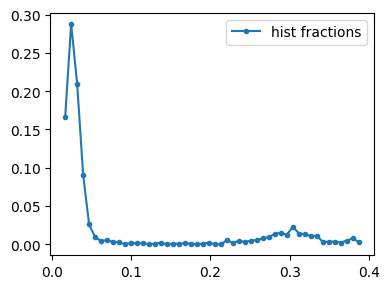

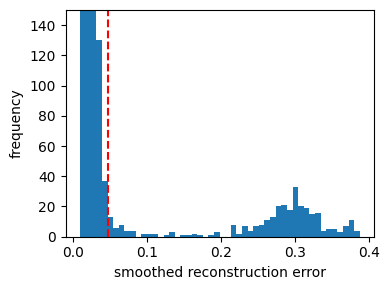

In [ ]:
# plot the relative fraction of the errors
fig=plt.figure(figsize=(4,3))
plt.plot(hist_re[1][1:],hist_re[0]/np.sum(hist_re[0]),'.-',label='hist fractions')
# define the histogram tail starting from a small fraction of 0.01
tail_start = np.min(np.where(hist_re[0]/np.sum(hist_re[0])<0.01)[0])
# find the value at the tail start
thresh_tail = hist_re[1][tail_start]
#sum over the frequqencies up to tail_start to estimate the number of anomalies
Nanomalies_est = np.sum(hist_re[0]) - np.sum(hist_re[0][:tail_start])
plt.legend()
plt.tight_layout()

fig=plt.figure(figsize=(4,3))
hist_re = plt.hist(moving_mean_errors,50)
plt.axvline(thresh_tail,color='r',linestyle='--')
plt.xlabel('smoothed reconstruction error')
plt.ylabel('frequency')
plt.ylim(0,150)
plt.tight_layout()

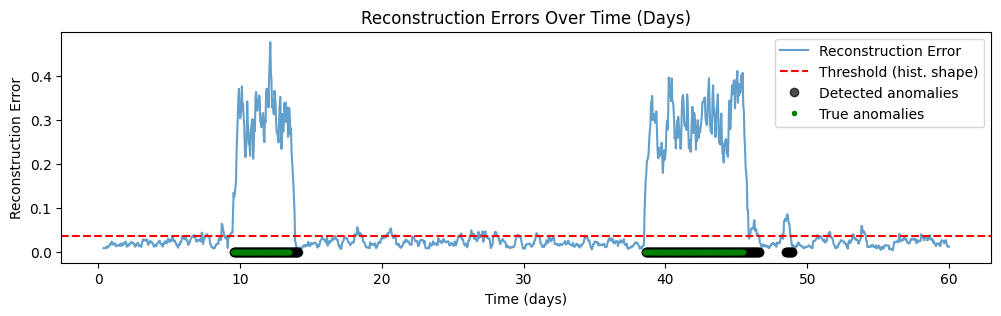

Threshold: 0.04675060418559909
Detected Anomalies: 315


In [ ]:
# Classify anomalies in the test set
test_anomalies = moving_mean_errors > thresh_tail

# Plot reconstruction errors vs. Time (days)
plt.figure(figsize=(12, 3))
plt.plot(test_window_timestamps, test_reconstruction_error, label="Reconstruction Error", alpha=0.7)
plt.axhline(threshold, color='red', linestyle='--', label=f"Threshold (hist. shape)")
plt.plot(test_window_timestamps[test_anomalies],0*test_window_timestamps[test_anomalies],'ok',label='Detected anomalies', alpha=0.7)
plt.plot(true_anomalies['Time (days)'],0*true_anomalies['Bearing Temperature'],'g.',label='True anomalies')

plt.xlabel("Time (days)")
plt.ylabel("Reconstruction Error")
plt.legend()
plt.title("Reconstruction Errors Over Time (Days)")
plt.show()

# Print summary of results
print("Threshold:", thresh_tail)
print("Detected Anomalies:", np.sum(test_anomalies))

# Evaluation and model comparison
We calculate the precision and recall for both models and compare them. This comparison is independent of the selected threshold.

In [ ]:
# time series model
anomaly_scores = moving_mean_errors
precision_test_ts, recall_test_ts = calculate_precision_recall_from_scratch(anomaly_scores, test_labels_win, threshold_arr)

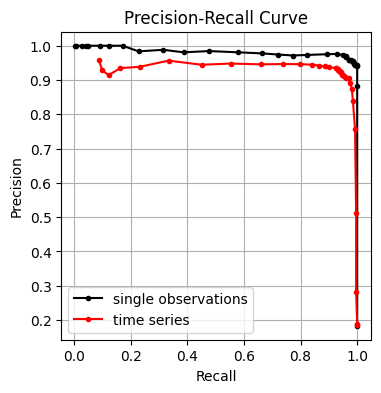

In [ ]:
plt.figure(figsize=(4, 4))
# single observations as input
plt.plot(recall_test,precision_test,'ko-',ms=3,label='single observations')
# timeseries as input
plt.plot(recall_test_ts,precision_test_ts,'ro-',ms=3,label='time series')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.grid()
plt.show()

## Plot detected anomalies on the time axis

Text(0, 0.5, 'Component temperature')

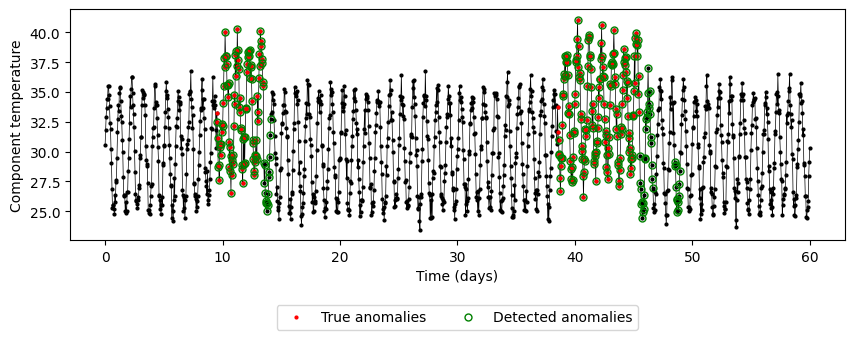

In [ ]:
# Highlight true anomalies with large empty yellow squares
#true_anomalies = data.loc[anomaly_mask]  # Use the indices of the true anomalies
detection_mask_test = moving_mean_errors > thresh_tail
detected_anomalies_test = test_data_reduced.loc[detection_mask_test]


plt.figure(figsize=(10,3))
plt.plot(data['Time (days)'],data['Bearing Temperature'],'k-o',lw=0.5,ms=2)
plt.plot(true_anomalies['Time (days)'],true_anomalies['Bearing Temperature'],'ro',ms=2,label='True anomalies')
plt.plot(test_window_timestamps[detection_mask_test],detected_anomalies_test['Bearing Temperature'],'go',markerfacecolor='none',ms=5,label='Detected anomalies')

plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.25), ncol=3)

plt.xlabel('Time (days)')
plt.ylabel('Component temperature')


## Think
1. Why doesn't smoothing help in the time series case?
2. Recall the hyperparameter we used (no. of principal components, smoothing window). Which one has a stronger effect on the results? Try to change it and compare the performance.
3. Can you study the triangle method for threshold setting and use it if and when possible?
